In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import torch

# Add the current directory to the path to ensure the notebook can find the local module
if os.path.abspath('.') not in sys.path:
    sys.path.append(os.path.abspath('.'))

from random_besov import FastWaveletBatchGenerator

In [2]:
###### Sampling Utilities
def sample_unit_ball(n, d):
    z = np.random.normal(size=(n, d))
    z /= np.linalg.norm(z, axis=1, keepdims=True)
    r = np.random.uniform(size=(n, 1)) ** (1 / d)
    return r * z


def sample_stiefel(d, p):
    if p > d:
        raise ValueError("p must be <= d")

    Z = np.random.normal(size=(d, p))
    Q, R = np.linalg.qr(Z)

    signs = np.sign(np.diag(R))
    signs[signs == 0] = 1
    Q *= signs
    return Q


def random_project(X, p):
    d = X.shape[1]
    U = sample_stiefel(d, p)
    X_projected = (np.matmul(X, U) + 1) / 2
    return X_projected

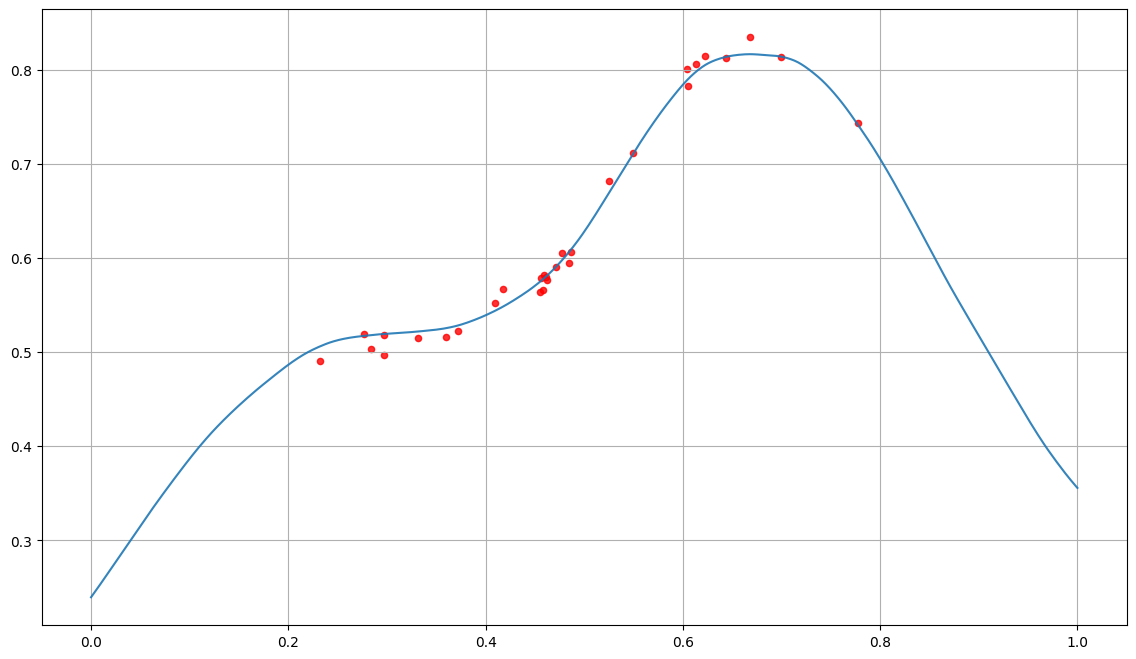

In [3]:
n = 30
n_test = 1000
d=5
X = sample_unit_ball(n+n_test, d)
X_train = X[:n, :]
X_test = X[n:(n+n_test), :]
X_projected = random_project(X, 1)
X_projected_and_grid = np.concatenate((X_projected, np.linspace(0, 1, 4096).reshape(-1, 1)), axis=0)

params = {'d': 1, 'alpha': 4, 'J': 10, 'C0': 2}
generator = FastWaveletBatchGenerator(wavelet='db6', cascade_level=8)
Y = generator.generate_batch([X_projected_and_grid], params)
generator.cleanup()
Y = Y[0]

Y[0:(n+n_test)] = Y[0:(n+n_test)] + np.random.normal(scale=0.01, size=Y[0:(n+n_test)].shape)
X_train_projected = X_projected_and_grid[:n].flatten()
X_test_projected = X_projected_and_grid[n:(n+n_test)].flatten()
y_train = Y[:n]
y_test = Y[n:(n+n_test)]
projected_grid = X_projected_and_grid[(n+n_test):,].flatten()
y_grid = Y[(n+n_test):,]

fig, ax = plt.subplots(figsize=(14, 8))
ax.plot(projected_grid, y_grid, alpha=0.9)
ax.scatter(X_train_projected, y_train, color="red", s=20, alpha=0.8)

ax.grid(True)
plt.show()

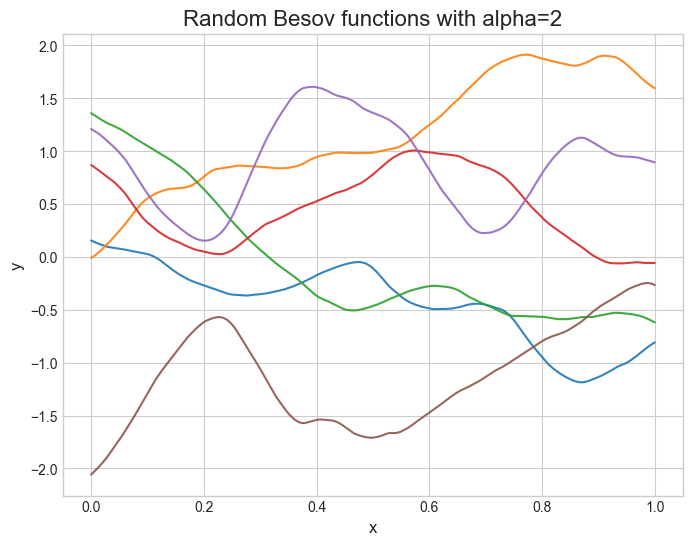

In [32]:
params = {'d': 1, 'alpha': 2, 'J': 10, 'C0': 2.0}
X_list = []
num_functions = 6
for i in range(num_functions):
    X_list.append(np.linspace(0, 1, 4096).reshape(-1, 1)) 



# Generate all functions in a single batch call
random_besov_generator = FastWaveletBatchGenerator(wavelet='db6', cascade_level=8)
Y_list = random_besov_generator.generate_batch(X_list, params)
random_besov_generator.cleanup()


# Plot the results
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(8, 6))

for i in range(num_functions):
    x_coords = X_list[i].flatten()
    y_coords = Y_list[i]
    alpha_val = params['alpha']
    ax.plot(x_coords, y_coords, label=f'Function {i+1} (alpha={alpha_val:.2f}, N={len(x_coords)})', alpha=0.9)

ax.set_title(f'Random Besov functions with alpha={alpha_val}', fontsize=16)
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('y', fontsize=12)
# ax.legend()
ax.grid(True)
plt.savefig("random_besov_alpha=2.pdf", bbox_inches='tight')
plt.show()

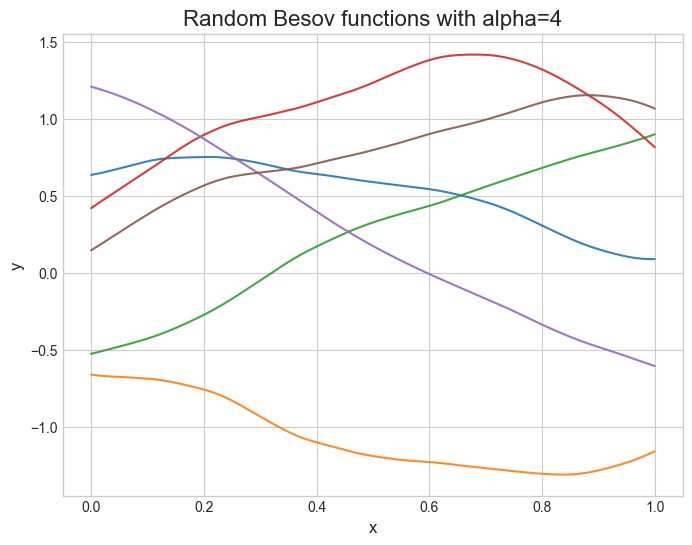

In [35]:
params = {'d': 1, 'alpha': 4, 'J': 10, 'C0': 2.0}
X_list = []
num_functions = 6
for i in range(num_functions):
    X_list.append(np.linspace(0, 1, 4096).reshape(-1, 1)) 



# Generate all functions in a single batch call
random_besov_generator = FastWaveletBatchGenerator(wavelet='db6', cascade_level=8)
Y_list = random_besov_generator.generate_batch(X_list, params)
random_besov_generator.cleanup()


# Plot the results
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(8, 6))

for i in range(num_functions):
    x_coords = X_list[i].flatten()
    y_coords = Y_list[i]
    alpha_val = params['alpha']
    ax.plot(x_coords, y_coords, label=f'Function {i+1} (alpha={alpha_val:.2f}, N={len(x_coords)})', alpha=0.9)

ax.set_title(f'Random Besov functions with alpha={alpha_val}', fontsize=16)
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('y', fontsize=12)
# ax.legend()
ax.grid(True)
plt.savefig("random_besov_alpha=4.pdf", bbox_inches='tight')
plt.show()